In [1]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import pickle
from scipy.stats import linregress, ttest_ind, fisher_exact, describe, mode, norm, sem
import os
import sys
from datetime import date
from sklearn.metrics import auc, f1_score
import random
from sklearn.decomposition import NMF, non_negative_factorization
import seaborn as sns
import time
from matplotlib.colors import LogNorm, Normalize
from mpl_toolkits.axes_grid1 import axes_grid

In [2]:
#load npz file
mixture_all_cycles = []

#original mixture
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Mixture.npy.gz', "r")
mixture_all_cycles.append(np.float32(np.load(fn)))

for i in range(1, 2):
    print(i)
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_booldhsarr_basis_mixture_to0thresh0.0_to1thresh1.0_cycle'+str(i)+'_CT20220323.npz'
    cycle_np_file = np.load(filename)
    mixture_all_cycles.append(cycle_np_file['new_decomp_mixture'])

mixture_all_cycles = np.array(mixture_all_cycles)

1


In [3]:
#load npz file
basis_all_cycles = []

#original mixture
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Basis.npy.gz', "r")
basis_all_cycles.append(np.float32(np.load(fn)))

for i in range(1, 2):
    print(i)
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_booldhsarr_basis_mixture_to0thresh0.0_to1thresh1.0_cycle'+str(i)+'_CT20220323.npz'
    cycle_np_file = np.load(filename)
    basis_all_cycles.append(cycle_np_file['new_decomp_basis'])

basis_all_cycles = np.array(basis_all_cycles)

1


In [4]:
n_components, n_DHSs = mixture_all_cycles[0].shape

In [ ]:
file = '/home/ctrader/NMF_data/DHS_signal_matrix/max_DHS_signal_hg38.75_20.normalized.GRCh38_no_alts_array_CT20220322.npy'
DHS_max_signal_array = np.load(file)

In [5]:
comps_for_heatmap = np.array(['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial'])
color = ['#FFE500', '#FE8102', '#FF0000', '#07AF00', '#4C7D14', '#414613', '#05C1D9', '#0467FD', '#009588', '#BB2DD4', '#7A00FF', '#4A6876', '#08245B', '#B9461D', '#692108', '#C3C3C3']
neworder = np.array([16,10,7,11,2,12,1,8,4,15,14,5,9,6,3,13]).astype(int) - 1
color = np.array(color)[neworder]

official_order = np.array([6, 4, 14, 8, 11, 13, 2, 7, 12, 1, 3, 5, 15, 10, 9, 0])

In [6]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])
DHS_metadata['mean_signal'] = DHS_metadata['mean_signal'].astype(float)

#top 10%
DHS_metadata['ind'] = DHS_metadata.index
DHS_metadata_sortby_mean_signal = DHS_metadata.sort_values(['mean_signal'], ascending=False)
top_10_percent_DHSs = DHS_metadata_sortby_mean_signal.iloc[:int(np.round(n_DHSs/10))]
top_10_percent_DHSs_inds = np.array(top_10_percent_DHSs['ind'])
top_10_percent_DHSs_identifiers = np.array(top_10_percent_DHSs['identifier'])

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [7]:
#loading biosample metadata
tsv_file = open("/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_metadata.tsv")
biosample_df = pd.read_csv(tsv_file, delimiter="\t")

In [8]:
#load npz file
added_recon_all_cycles = []
removed_recon_all_cycles = []
added_flat_inds_all_cycles = []
removed_flat_inds_all_cycles = []

for i in range(1, 2):
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_added_removed_recon_flatinds_to0thresh0.0_to1thresh1.0_cycle'+str(i)+'_CT20220323.npz'
    cycle_np_file = np.load(filename)
    added_recon_all_cycles.append(cycle_np_file['added_recon'])
    removed_recon_all_cycles.append(cycle_np_file['removed_recon'])
    added_flat_inds_all_cycles.append(cycle_np_file['added_flat_inds'])
    removed_flat_inds_all_cycles.append(cycle_np_file['removed_flat_inds'])

In [168]:
#The component number for the summary data corresponds to the NMF component
comp0 = pd.read_table('/home/ctrader/lightfm_data/comp1_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp0 mean'])
comp1 = pd.read_table('/home/ctrader/lightfm_data/comp2_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp1 mean'])
comp2 = pd.read_table('/home/ctrader/lightfm_data/comp3_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp2 mean'])
comp3 = pd.read_table('/home/ctrader/lightfm_data/comp4_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp3 mean'])
comp4 = pd.read_table('/home/ctrader/lightfm_data/comp5_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp4 mean'])
comp5 = pd.read_table('/home/ctrader/lightfm_data/comp6_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp5 mean'])
comp6 = pd.read_table('/home/ctrader/lightfm_data/comp7_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp6 mean'])
comp7 = pd.read_table('/home/ctrader/lightfm_data/comp8_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp7 mean'])
comp8 = pd.read_table('/home/ctrader/lightfm_data/comp9_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp8 mean'])
comp9 = pd.read_table('/home/ctrader/lightfm_data/comp10_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp9 mean'])
comp10 = pd.read_table('/home/ctrader/lightfm_data/comp11_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp10 mean'])
comp11 = pd.read_table('/home/ctrader/lightfm_data/comp12_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp11 mean'])
comp12 = pd.read_table('/home/ctrader/lightfm_data/comp13_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp12 mean'])
comp13 = pd.read_table('/home/ctrader/lightfm_data/comp14_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp13 mean'])
comp14 = pd.read_table('/home/ctrader/lightfm_data/comp15_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp14 mean'])
comp15 = pd.read_table('/home/ctrader/lightfm_data/comp16_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp15 mean'])

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (0) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [169]:
all_comps_average_signal = comp0[['name', 'comp0 mean']].merge(comp1[['name', 'comp1 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp2[['name', 'comp2 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp3[['name', 'comp3 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp4[['name', 'comp4 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp5[['name', 'comp5 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp6[['name', 'comp6 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp7[['name', 'comp7 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp8[['name', 'comp8 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp9[['name', 'comp9 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp10[['name', 'comp10 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp11[['name', 'comp11 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp12[['name', 'comp12 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp13[['name', 'comp13 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp14[['name', 'comp14 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp15[['name', 'comp15 mean']], how='inner', on='name')
all_comps_average_signal['average over all comps'] = all_comps_average_signal.mean(axis=1)
# all_comps_average_signal['average over all comps'] = (all_comps_average_signal['comp0 mean'] + all_comps_average_signal['comp1 mean'] + all_comps_average_signal['comp2 mean'] + all_comps_average_signal['comp3 mean'] + all_comps_average_signal['comp4 mean'] + all_comps_average_signal['comp5 mean'] + all_comps_average_signal['comp6 mean'] + all_comps_average_signal['comp7 mean'] + all_comps_average_signal['comp8 mean'] + all_comps_average_signal['comp9 mean'] + all_comps_average_signal['comp10 mean'] + all_comps_average_signal['comp11 mean'] + all_comps_average_signal['comp12 mean'] + all_comps_average_signal['comp13 mean'] + all_comps_average_signal['comp14 mean'] + all_comps_average_signal['comp15 mean'])/16
all_comps_average_signal['name'] = all_comps_average_signal['name'].astype(str)
all_comps_average_signal = all_comps_average_signal.set_index(['name'])
# old_columns = list(all_comps_average_signal.columns).extend(['max signal'])
# all_comps_average_signal.columns = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
all_comps_average_signal['max signal'] = all_comps_average_signal.idxmax(axis=1)
# all_comps_average_signal.columns = old_columns

DHS_metadata_identifiers = np.array(DHS_metadata['identifier'])

all_comps_average_signal = all_comps_average_signal.loc[DHS_metadata_identifiers]
top_10_percent_T_F = np.array([False]*len(all_comps_average_signal))
top_10_percent_T_F[top_10_percent_DHSs_inds] = True
all_comps_average_signal['top 10 percent'] = top_10_percent_T_F
all_comps_average_signal

/tmp/ipykernel_45587/4162047146.py:16: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  all_comps_average_signal['average over all comps'] = all_comps_average_signal.mean(axis=1)


,comp0 mean,comp1 mean,comp2 mean,comp3 mean,comp4 mean,comp5 mean,comp6 mean,comp7 mean,comp8 mean,comp9 mean,comp10 mean,comp11 mean,comp12 mean,comp13 mean,comp14 mean,comp15 mean,average over all comps,max signal,top 10 percent
name,,,,,,,,,,,,,,,,,,,
1.10011,0.053318,0.046712,0.039907,0.034054,0.029935,0.019642,0.050381,0.044771,0.038645,0.052703,0.028230,0.073723,0.043809,0.059390,0.188392,0.038370,0.052624,comp14 mean,False
1.10021,0.012199,0.006616,0.009675,0.005551,0.009631,0.015424,0.037962,0.003689,0.003913,0.006651,0.014848,0.009479,0.012386,0.008923,0.008113,0.004985,0.010628,comp6 mean,False
1.10025,0.013972,0.010649,0.002742,0.005082,0.004388,0.004117,0.010228,0.085321,0.003772,0.005397,0.006319,0.011102,0.003377,0.002977,0.005027,0.015383,0.011866,comp7 mean,False
1.10027,0.002374,0.003701,0.025612,0.018267,0.005331,0.021985,0.032393,0.008670,0.010130,0.010930,0.006678,0.003414,0.000000,0.005247,0.015185,0.002535,0.010778,comp6 mean,False
1.1003,0.017845,0.008636,0.009204,0.007383,0.013745,0.008851,0.032531,0.006222,0.006340,0.007592,0.031536,0.004111,0.014399,0.013492,0.006270,0.012739,0.012556,comp6 mean,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Y.994281,0.016663,0.013051,0.006976,0.008886,0.013321,0.019894,0.044953,0.010084,0.012202,0.006862,0.017083,0.012507,0.017318,0.012432,0.019537,0.017870,0.015602,comp6 mean,False
Y.994286,0.003373,0.007940,0.003355,0.002987,0.008398,0.005565,0.007886,0.005332,0.002115,0.004837,0.001810,0.005148,0.001989,0.004099,0.007139,0.003393,0.004710,comp4 mean,False
Y.994292,0.034594,0.021025,0.013023,0.017206,0.024326,0.086499,0.231924,0.011905,0.017295,0.018428,0.025081,0.018944,0.029714,0.030595,0.021135,0.143163,0.046554,comp6 mean,False


In [9]:
#top comps
basis_all_cycles_top_comp = np.argmax(basis_all_cycles, axis=2)
basis_all_cycles_top_comp_val = np.max(basis_all_cycles, axis=2)

#sum
basis_all_cycles_sum = np.sum(basis_all_cycles, axis=2)

In [10]:
mixture_all_cycles_top_comp = np.argmax(mixture_all_cycles, axis=1)

In [35]:
removed_DHS_inds = removed_flat_inds_all_cycles[0]%n_DHSs
added_DHS_inds = added_flat_inds_all_cycles[0]%n_DHSs

removed_biosample_inds = removed_flat_inds_all_cycles[0]//n_DHSs
added_biosample_inds = added_flat_inds_all_cycles[0]//n_DHSs

In [12]:
flipped_DHS_inds = np.append(added_DHS_inds, removed_DHS_inds)
flipped_biosample_inds = np.append(added_biosample_inds, removed_biosample_inds)

In [13]:
np.bincount(np.bincount(flipped_DHS_inds))

array([3533371,   48825,    7197,    1348,     312,     106,      28,
             6,       4,       1])

In [14]:
np.bincount(np.bincount(flipped_DHS_inds)[np.bincount(flipped_DHS_inds)!=0])

array([    0, 48825,  7197,  1348,   312,   106,    28,     6,     4,
           1])

**Flipped calls per biosample**

In [13]:
def histogram_wrapper(data):
    fig = plt.figure()
    fig.patch.set_facecolor('white')
    
    data_min = np.min(data)
    data_max = np.max(data)
#     data_counts = np.zeros(data_max-data_min+1)
#     for i in range(data_min, data_max+1):
#         data_counts[i-data_min] = len(data[data==i])
    data_counts = np.bincount(data)

    plt.fill_between(np.arange(data_min, data_max+1), data_counts, step='pre', alpha=1)
    plt.plot(np.arange(data_min, data_max+1), data_counts, drawstyle="steps")
    
    return fig

Text(0.5, 1.0, 'Calls Removed for Each Biosample')

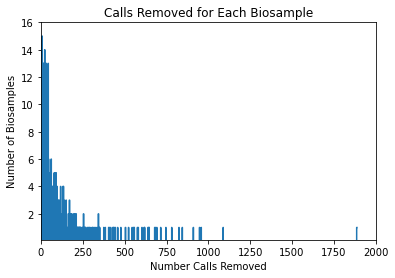

In [254]:
fig = histogram_wrapper(np.bincount(flipped_biosample_inds))
plt.xlim([0, 2000])
plt.ylim([0.1, 16])
plt.ylabel('Number of Biosamples')
plt.xlabel('Number Calls Removed')
plt.title('Calls Removed for Each Biosample')

In [17]:
np.bincount(flipped_biosample_inds).shape

(733,)

In [112]:
describe(np.bincount(flipped_biosample_inds))

DescribeResult(nobs=733, minmax=(0, 1887), mean=94.53206002728513, variance=25280.530733045576, skewness=4.449513028801296, kurtosis=30.02908544929295)

In [107]:
mode(np.bincount(flipped_biosample_inds))

ModeResult(mode=array([7]), count=array([15]))

In [58]:
#DHSs sent to Arpita 5/23/22
np.save('/home/ctrader/NMF_data/most_flipped_DHSs_for_scoring/reconstructed_threshold_flip_most_flipped_DHSs_to0thresh0.0_to1thresh1.0_cycle1_CT20220523.npz', np.argsort(-np.bincount(flipped_DHS_inds))[:145])

In [357]:
np.argsort(-np.bincount(flipped_biosample_inds))[:10]

array([ 44, 715, 102, 480, 601, 319, 600, 602, 643, 651])

In [28]:
biosample_df.loc[np.argsort(-np.bincount(flipped_biosample_inds))[:10]]

,library order,Biosample name,Vocabulary representative,DCC Experiment ID,DCC Library ID,DCC Biosample ID,Altius Aggregation ID,Altius Library ID,Altius Biosample ID,Replicate indicators,...,Library cleanup,DNaseI units/mL,Amount Nucleic Acid (ng),Nuclei count,Protease inhibitor,Library sequencing date,Reads used,DCC SPOT score,Per-biosample peaks,DHSs in Index
44,45,hESCT0,Primitive / embryonic,ENCSR000EMZ,ENCLB449ZZZ,ENCBS293AAA,AG4188,LN2365,DS11909,DS13133,...,minElute,80.0,14,NaN,NaN,2009-08-19,240791918,0.6453,315568,314868
715,716,DE,Primitive / embryonic,ENCSR166KPV,ENCLB393NTX,ENCBS088TSK,AG6944,LN43606A,DS55923A,DS39603C,...,NaN,NaN,1.1,540000.0,NaN,2017-01-05,457497776,0.5445,312848,307202
102,103,NHLF,Stromal B,ENCSR000EPR,ENCLB569ZZZ,ENCBS340AAA,AG4141,LN2632,DS12829,DS12834,...,minElute,120.0,8.8,NaN,NaN,2009-11-02,288918603,0.7161,293067,292691
480,481,Small_Intestine_Mucosa,Digestive,ENCSR931UQB,ENCLB776CXK,ENCBS853LFM,AG8858,LN4899,DS20770,NaN,...,minElute,60.0,63.7,6750000.0,A+Sucrose,2011-10-21,261183925,0.4702,187693,187198
601,602,fTongue,Musculoskeletal,ENCSR759UNY,ENCLB323PCN,ENCBS321GUH,AG3923,LN21290A,DS24808A,NaN,...,Sucrose,70.0,3.1,2790000.0,A+Sucrose,2013-10-24,368107814,0.4150,233230,232547
319,320,fMuscle_back,Musculoskeletal,ENCSR317SIH,ENCLB752ROB,ENCBS384LIR,AG9007,LN4072,DS17767,NaN,...,minElute,80.0,24,3600000.0,A+Sucrose,2011-01-13,348976677,0.5563,227382,225627
600,601,fSpinal_cord,Neural,ENCSR910OQF,ENCLB216GJK,ENCBS665NIQ,AG3922,LN21289A,DS24833A,NaN,...,Sucrose,60.0,1.8,4500000.0,A+Sucrose,2013-10-24,654629469,0.4399,298953,297421
602,603,fTongue,Musculoskeletal,ENCSR559WMK,ENCLB329UJC,ENCBS377XXD,AG3912,LN21292A,DS24888A,NaN,...,Sucrose,80.0,2.6,2610000.0,A+Sucrose,2013-11-05,359729577,0.4597,227994,227286
643,644,fHeart,Cardiac,ENCSR664PKM,ENCLB434QXK,ENCBS910QFW,AG3958,LN26948A,DS24812A,NaN,...,Sucrose,NaN,5.89,560000.0,A+Sucrose,2013-10-15,492718541,0.3958,200817,199314
651,652,Trophoblast,Placental / trophoblast,ENCSR121ZSL,ENCLB873PCM,ENCBS627LRI,AG3818,LN28076A,DS30587A,DS35778S,...,NaN,NaN,4,720000.0,PBS+A,2014-08-19,666187813,0.5675,355914,354918


In [13]:
#comp enrichments
expected_comp_ratio = np.bincount(mixture_all_cycles_top_comp[0])/len(mixture_all_cycles_top_comp[0])

In [14]:
def comp_enrichment_wrapper(data):
    fig = plt.figure(figsize=(6,3))
    fig.patch.set_facecolor('white')
    
    official_order_data = data[official_order]
    c = color[official_order]
    
    plt.bar(np.arange(len(data)), official_order_data, color=c)
    plt.xlim([-0.5, 15.5])
    
#     handles = [plt.Rectangle((0,0),1,1, color=color[i]) for i in official_order]
#     plt.legend(handles, comps_for_heatmap[official_order], loc=(1.01, 0.1))
    
#     plt.plot([-1, 16], [0, 0], 'k', linewidth=1)
    plt.xticks([])
    
    plt.xlabel('Component')
    plt.ylabel('Enrichment')
    
    return fig

In [15]:
def removed_max_signal_info_wrapper(ind):
    removed_ind_DHS_inds = removed_DHS_inds[removed_biosample_inds==ind]
    removed_ind_biosample_inds = removed_biosample_inds[removed_biosample_inds==ind]
    removed_ind_max_signal = DHS_max_signal_array[removed_ind_biosample_inds, removed_ind_DHS_inds]
    print(describe(removed_ind_max_signal))
    print(mode(removed_ind_max_signal))
    return removed_ind_max_signal

In [16]:
def added_max_signal_info_wrapper(ind):
    added_ind_DHS_inds = added_DHS_inds[added_biosample_inds==ind]
    added_ind_biosample_inds = added_biosample_inds[added_biosample_inds==ind]
    added_ind_max_signal = DHS_max_signal_array[added_ind_biosample_inds, added_ind_DHS_inds]
    print(describe(added_ind_max_signal))
    print(mode(added_ind_max_signal))
    return added_ind_max_signal

In [17]:
def removed_max_signal_info_wrapper_by_comp(ind):
    removed_ind_DHS_inds = removed_DHS_inds[removed_biosample_inds==ind]
    removed_ind_biosample_inds = removed_biosample_inds[removed_biosample_inds==ind]
    removed_ind_comps = mixture_all_cycles_top_comp[0, removed_ind_DHS_inds]
    comp_signal_means = np.zeros(16)*np.nan
    for i in range(16):
        comp_specific_removed_ind_DHS_inds = removed_ind_DHS_inds[removed_ind_comps==i]
        comp_specific_removed_ind_biosample_inds = removed_ind_biosample_inds[removed_ind_comps==i]
        comp_specific_max_signal = DHS_max_signal_array[comp_specific_removed_ind_biosample_inds, 
                                                        comp_specific_removed_ind_DHS_inds]
        if len(comp_specific_max_signal>0):
            comp_signal_means[i]=np.mean(comp_specific_max_signal)
        
    return comp_signal_means

In [18]:
def added_max_signal_info_wrapper_by_comp(ind):
    added_ind_DHS_inds = added_DHS_inds[added_biosample_inds==ind]
    added_ind_biosample_inds = added_biosample_inds[added_biosample_inds==ind]
    added_ind_comps = mixture_all_cycles_top_comp[0, added_ind_DHS_inds]
    comp_signal_means = np.zeros(16)*np.nan
    for i in range(16):
        comp_specific_added_ind_DHS_inds = added_ind_DHS_inds[added_ind_comps==i]
        comp_specific_added_ind_biosample_inds = added_ind_biosample_inds[added_ind_comps==i]
        comp_specific_max_signal = DHS_max_signal_array[comp_specific_added_ind_biosample_inds, 
                                                        comp_specific_added_ind_DHS_inds]
        if len(comp_specific_max_signal>0):
            comp_signal_means[i]=np.mean(comp_specific_max_signal)
        
    return comp_signal_means

In [40]:
# np.max(np.bincount(flipped_DHS_inds))

**Enrichment of the top component of all biosamples**

In [20]:
biosamples_num_added_ordered = np.argsort(-np.bincount(added_biosample_inds))

#adding biosamples not picked up by bincount
biosamples_num_added_ordered = np.append(biosamples_num_added_ordered, [730, 731, 732])

biosamples_num_added_ordered_top_comps = []
biosamples_num_added_ordered_top_comp_added_DHS_enrichment = []
for biosample in biosamples_num_added_ordered:
    #counting the added DHSs of each component
    added_biosample_top_DHS_comps = np.bincount(mixture_all_cycles_top_comp[0][added_DHS_inds[np.where(added_biosample_inds==biosample)[0]]])
    #adding 0s to comps that didn't get picked up by bincount
    added_biosample_top_DHS_comps = np.append(added_biosample_top_DHS_comps, 
                                              np.array([0]*(16-len(added_biosample_top_DHS_comps)))).astype(int)
    #enrichment of added DHSs for each comp
    added_biosample_top_DHS_comps_enrichments = (added_biosample_top_DHS_comps / np.sum(added_biosample_top_DHS_comps)) / expected_comp_ratio
    
    #top comp BEFORE flipping
    top_comp = basis_all_cycles_top_comp[0, biosample]
#     print(biosample, top_comp)
    top_comp_enrichment = added_biosample_top_DHS_comps_enrichments[top_comp]
    biosamples_num_added_ordered_top_comps.append(top_comp)
    biosamples_num_added_ordered_top_comp_added_DHS_enrichment.append(top_comp_enrichment)
biosamples_num_added_ordered_top_comps = np.array(biosamples_num_added_ordered_top_comps)
biosamples_num_added_ordered_top_comp_added_DHS_enrichment = np.array(biosamples_num_added_ordered_top_comp_added_DHS_enrichment)

/tmp/ipykernel_184732/3769083705.py:15: RuntimeWarning: invalid value encountered in true_divide
  added_biosample_top_DHS_comps_enrichments = (added_biosample_top_DHS_comps / np.sum(added_biosample_top_DHS_comps)) / expected_comp_ratio


/tmp/ipykernel_152841/2889415482.py:5: RuntimeWarning: divide by zero encountered in log2
  np.log2(biosamples_num_added_ordered_top_comp_added_DHS_enrichment)[:100],


Text(0.5, 1.0, 'Enrichment of Added Calls in Top Component of 100 Biosamples')

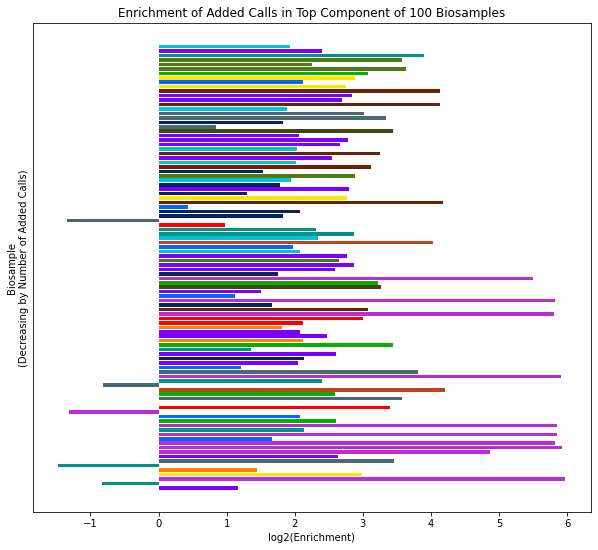

In [59]:
fig = plt.figure(figsize=(10,9))
fig.patch.set_facecolor('white')

plt.barh(np.arange(len(biosamples_num_added_ordered_top_comp_added_DHS_enrichment))[::-1][:100], 
         np.log2(biosamples_num_added_ordered_top_comp_added_DHS_enrichment)[:100],
         color=color[biosamples_num_added_ordered_top_comps],
         align='center')

plt.yticks([])
plt.ylabel('Biosample\n(Decreasing by Number of Added Calls)')
plt.xlabel('log2(Enrichment)')
plt.title('Enrichment of Added Calls in Top Component of 100 Biosamples')

/tmp/ipykernel_152841/4043010194.py:5: RuntimeWarning: divide by zero encountered in log2
  np.log2(biosamples_num_added_ordered_top_comp_added_DHS_enrichment),


Text(0.5, 1.0, 'Enrichment of Added Calls in Top Component of All Biosamples')

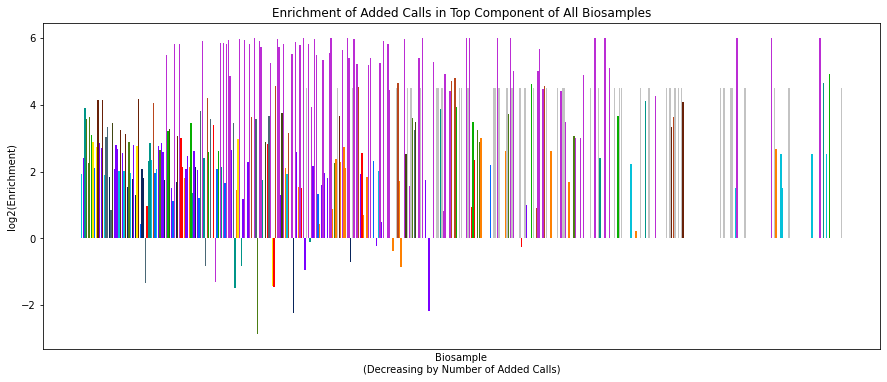

In [60]:
fig = plt.figure(figsize=(15,6))
fig.patch.set_facecolor('white')

plt.bar(np.arange(len(biosamples_num_added_ordered_top_comp_added_DHS_enrichment)), 
        np.log2(biosamples_num_added_ordered_top_comp_added_DHS_enrichment),
        color=color[biosamples_num_added_ordered_top_comps],
        align='center')

plt.xticks([])
plt.xlabel('Biosample\n(Decreasing by Number of Added Calls)')
plt.ylabel('log2(Enrichment)')
plt.title('Enrichment of Added Calls in Top Component of All Biosamples')

In [21]:
#basis purity
basis_cycle0_norm = (basis_all_cycles[0, :, :].T/np.sum(basis_all_cycles[0, :], axis=1)).T
basis_cycle0_norm_sorted = -np.sort(-basis_cycle0_norm, axis=1)
basis_all_cycles_by_normdiff_purity = basis_cycle0_norm_sorted[:, 0] - basis_cycle0_norm_sorted[:, 1]


# basis_all_cycles_by_sum_purity = np.max(basis_all_cycles, axis=2) / np.sum(basis_all_cycles, axis=2)

Text(0.5, 1.0, 'Enrichment of Added Calls with Biosample NMF Purity')

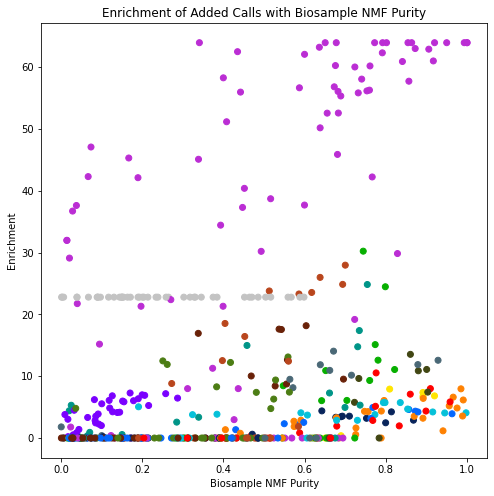

In [22]:
fig = plt.figure(figsize=(8,8))
fig.patch.set_facecolor('white')

plt.scatter(basis_all_cycles_by_normdiff_purity[biosamples_num_added_ordered], 
            biosamples_num_added_ordered_top_comp_added_DHS_enrichment,
            color=color[biosamples_num_added_ordered_top_comps])

plt.xlabel('Biosample NMF Purity')
plt.ylabel('Enrichment')
plt.title('Enrichment of Added Calls with Biosample NMF Purity')

In [243]:
#interestingly, all biosamples with top comp = 0 only adds to 0 DHSs
np.log2(1/expected_comp_ratio[0])

4.509766293513255

In [63]:
comp_specific_ave_enrichment = []
for comp in range(16):
    top_comp_specific_local_inds = np.where(biosamples_num_added_ordered_top_comps==comp)[0]
    comp_specific_enrichments = biosamples_num_added_ordered_top_comp_added_DHS_enrichment[top_comp_specific_local_inds]
    mean_comp_specific_enrichments = np.nanmean(comp_specific_enrichments)
    comp_specific_ave_enrichment.append(mean_comp_specific_enrichments)
comp_specific_ave_enrichment = np.array(comp_specific_ave_enrichment)
comp_specific_ave_enrichment_dict = {
    'Component' : comps_for_heatmap,
    'Enrichment' : comp_specific_ave_enrichment
}
comp_specific_ave_enrichment_df = pd.DataFrame(comp_specific_ave_enrichment_dict)
comp_specific_ave_enrichment_df

,Component,Enrichment
0,Tissue invariant,22.781112
1,Stromal A,38.305906
2,Primitive / embryonic,2.793241
3,Stromal B,4.270961
4,Lymphoid,3.062389
5,Renal / cancer,5.403247
6,Placental / trophoblast,3.649165
7,Neural,1.048866
8,Cardiac,7.065728
9,Organ devel. / renal,3.518075


Text(0.5, 1.0, 'Average Enrichment for Added Calls\nin Top Component of Biosamples')

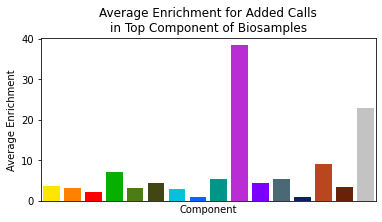

In [64]:
fig = plt.figure(figsize=(6,3))
fig.patch.set_facecolor('white')

official_order_comp_specific_ave_enrichment = comp_specific_ave_enrichment[official_order]
c = color[official_order]

plt.bar(np.arange(len(official_order_comp_specific_ave_enrichment)), 
        official_order_comp_specific_ave_enrichment, 
        color=c)
plt.xlim([-0.5, 15.5])

plt.xticks([])

plt.xlabel('Component')
plt.ylabel('Average Enrichment')
plt.title('Average Enrichment for Added Calls\nin Top Component of Biosamples')

**Comparing reconstruction to orginal**

In [39]:
reconstruction = np.dot(basis_all_cycles[0], mixture_all_cycles[0])

In [40]:
reconstruction_bin = np.where(reconstruction>0.35, 1, 0)

In [41]:
cycle0_dhs_arr = np.load('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38_bool_array.npy')

In [251]:
# np.sum(cycle0_dhs_arr, axis=1)

In [42]:
num_biosamples_per_DHS_recon = np.sum(reconstruction_bin, axis=0)
num_biosamples_per_DHS_ori = np.sum(cycle0_dhs_arr, axis=0)

In [43]:
np.where(num_biosamples_per_DHS_recon==0)[0].shape

(2605767,)

Text(0.5, 1.0, 'Number of Calls for Each DHS in Original and Reconstructed Matrix')

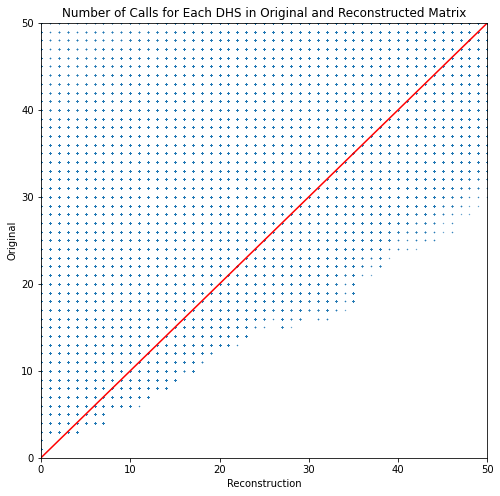

In [55]:
fig = plt.figure(figsize=(8,8))
fig.patch.set_facecolor('white')

plt.scatter(num_biosamples_per_DHS_recon, 
            num_biosamples_per_DHS_ori, 
            s=0.1)
plt.plot([0, 733], [0, 733], c='r')

plt.xlim([0, 50])
plt.ylim([0, 50])
plt.xlabel('Reconstruction')
plt.ylabel('Original')
plt.title('Number of Calls for Each DHS in Original and Reconstructed Matrix')

Text(0.5, 0.93, 'Number of Positive Biosamples for Each DHS')

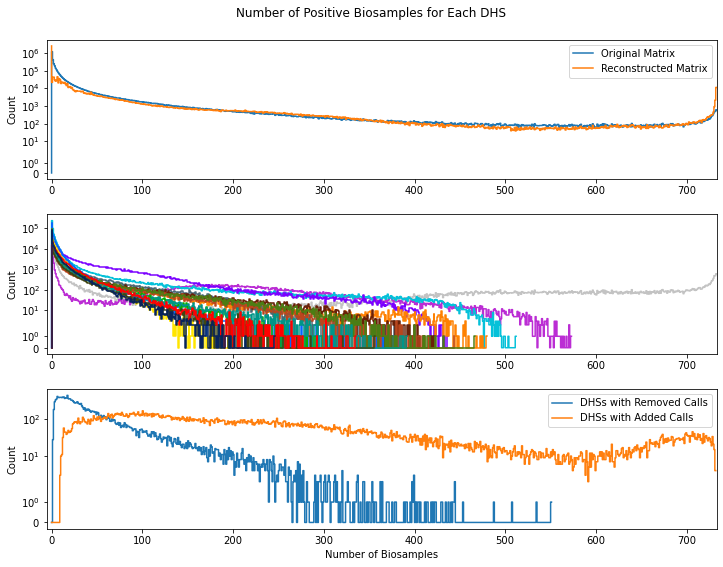

In [51]:
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(12,9))
fig.patch.set_facecolor('white')
fig.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=None, hspace=0.25)

axes = axes.ravel()

y = np.bincount(num_biosamples_per_DHS_ori)
x = np.arange(len(y))
axes[0].step(x, y)

y = np.bincount(num_biosamples_per_DHS_recon)
x = np.arange(len(y))
axes[0].step(x, y)

axes[0].set_ylabel('Count')
# axes[0].set_ylim([0, 5000])
axes[0].set_xlim([-5, 733])
axes[0].legend(['Original Matrix', 'Reconstructed Matrix'])
axes[0].set_yscale('symlog')


for comp in range(16):
    dhss_with_top_comp = np.where(mixture_all_cycles_top_comp[0, :]==comp)[0]
    y = np.bincount(num_biosamples_per_DHS_ori[dhss_with_top_comp])
    x = np.arange(len(y))
    axes[1].step(x, y, c=color[comp])
# axes[1].set_ylim([0, 1000])
axes[1].set_ylabel('Count')
axes[1].set_xlim([-5, 733])
axes[1].set_yscale('symlog')

y = np.bincount(num_biosamples_per_DHS_ori[np.unique(removed_DHS_inds)])
x = np.arange(len(y))
axes[2].step(x, y)

y = np.bincount(num_biosamples_per_DHS_ori[np.unique(added_DHS_inds)])
x = np.arange(len(y))
axes[2].step(x, y)

axes[2].set_xlabel('Number of Biosamples')
axes[2].set_ylabel('Count')
# axes[2].set_ylim([-0.5, 475])
axes[2].set_xlim([-5, 733])
axes[2].legend(['DHSs with Removed Calls', 'DHSs with Added Calls'])
axes[2].set_yscale('symlog')

plt.suptitle('Number of Positive Biosamples for Each DHS', y=0.93)

In [7]:
recon_1s_cycle0 = reconstruction[cycle0_dhs_arr]
recon_0s_cycle0 = reconstruction[~cycle0_dhs_arr]

In [8]:
recon_1s_cycle0_r2 = np.round(recon_1s_cycle0, 2)
recon_0s_cycle0_r2 = np.round(recon_0s_cycle0, 2)

In [9]:
del recon_1s_cycle0
del recon_0s_cycle0

In [16]:
recon_1s_cycle0_r2[recon_1s_cycle0_r2<0.5].shape

(34451575,)

In [17]:
recon_1s_cycle0_r2[recon_1s_cycle0_r2>0.5].shape

(41204704,)

In [18]:
describe(recon_1s_cycle0_r2)

DescribeResult(nobs=76277537, minmax=(0.0, 2.36), mean=0.5638218, variance=0.12326937, skewness=0.14277284641683227, kurtosis=-0.9952193706430963)

In [30]:
recon_1s_cycle0_r2[((recon_1s_cycle0_r2>0.9) & (recon_1s_cycle0_r2<1.1))].shape

(12795033,)

In [10]:
recon_1s_cycle0_r2_vals, recon_1s_cycle0_r2_counts = np.unique(recon_1s_cycle0_r2, return_counts = True)
recon_0s_cycle0_r2_vals, recon_0s_cycle0_r2_counts = np.unique(recon_0s_cycle0_r2, return_counts = True)

Text(0.5, 0.97, 'Reconstruction Values for Positive and Negative Calls')

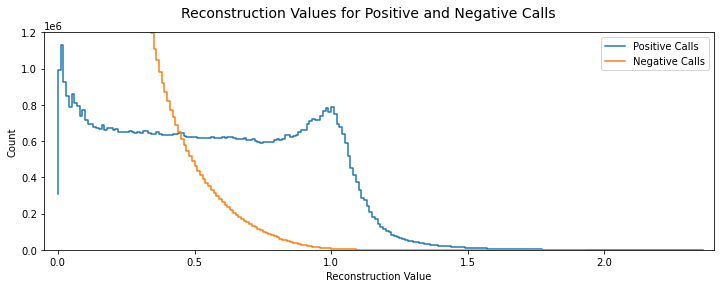

In [14]:
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(12,4))
fig.patch.set_facecolor('white')
fig.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=None, hspace=0.25)

# axes = axes.ravel()

axes.step(recon_1s_cycle0_r2_vals, recon_1s_cycle0_r2_counts)
axes.set_xlim([-0.05, 2.4])
axes.set_ylim([0, 1.2e6])
# axes[0].set_title('Positive Calls')

axes.step(recon_0s_cycle0_r2_vals, recon_0s_cycle0_r2_counts)
# axes[0].set_xlim([-0.05, 2.4])
# axes[0].set_ylim([0, 1.2e6])
# axes[0].set_title('Negative Calls')

axes.set_xlabel('Reconstruction Value')
axes.set_ylabel('Count')
# axes[1].set_ylabel('Count')
axes.legend(['Positive Calls', 'Negative Calls'])

plt.suptitle('Reconstruction Values for Positive and Negative Calls', y=0.97, fontsize=14)

In [21]:
#limit 1s and 0s to just DHSs with 5 or less biosamples
DHS_mask_less_equal_5_bio = np.where(num_biosamples_per_DHS_ori<=5)[0]
recon_1s_cycle0_5mask = reconstruction[:, DHS_mask_less_equal_5_bio][cycle0_dhs_arr[:, DHS_mask_less_equal_5_bio]]
recon_0s_cycle0_5mask = reconstruction[:, DHS_mask_less_equal_5_bio][~cycle0_dhs_arr[:, DHS_mask_less_equal_5_bio]]

recon_1s_cycle0_5mask_r2 = np.round(recon_1s_cycle0_5mask, 2)
recon_0s_cycle0_5mask_r2 = np.round(recon_0s_cycle0_5mask, 2)
del recon_0s_cycle0_5mask
del recon_1s_cycle0_5mask

recon_1s_cycle0_5mask_r2_vals, recon_1s_cycle0_5mask_r2_counts = np.unique(recon_1s_cycle0_5mask_r2, return_counts = True)
recon_0s_cycle0_5mask_r2_vals, recon_0s_cycle0_5mask_r2_counts = np.unique(recon_0s_cycle0_5mask_r2, return_counts = True)

Text(0.5, 1, 'Reconstruction Values for Positive and Negative\n Calls in DHSs with 5 or Less Biosamples')

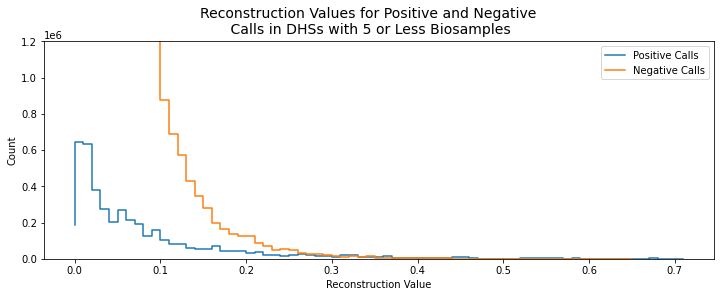

In [37]:
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(12,4))
fig.patch.set_facecolor('white')
fig.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=None, hspace=0.25)

# axes = axes.ravel()

axes.step(recon_1s_cycle0_5mask_r2_vals, recon_1s_cycle0_5mask_r2_counts)
# axes.set_xlim([-0.05, 2.4])
axes.set_ylim([0, 1.2e6])

axes.step(recon_0s_cycle0_5mask_r2_vals, recon_0s_cycle0_5mask_r2_counts)

axes.set_xlabel('Reconstruction Value')
axes.set_ylabel('Count')
# axes[1].set_ylabel('Count')
axes.legend(['Positive Calls', 'Negative Calls'])

plt.suptitle('Reconstruction Values for Positive and Negative\n Calls in DHSs with 5 or Less Biosamples', y=1, fontsize=14)

In [12]:
#creating a matrix counting the number of positive calls for each DHS
num_biosamples_per_DHS_ori_m = np.tile(num_biosamples_per_DHS_ori, (733, 1))
#creating a matrix for basis top components per biosample
basis_top_comp_per_biosample_m = np.tile(basis_all_cycles_top_comp[0].reshape(733, 1), (n_DHSs))
#creating a matrix for mixture top components per DHS
mixture_top_comp_per_DHS_m = np.tile(mixture_all_cycles_top_comp[0], (733, 1))

#for positive calls, finding the number of biosamples and recon values as arrays
pos_call_num_biosamples_arr = num_biosamples_per_DHS_ori_m[cycle0_dhs_arr]
pos_call_recon_arr = reconstruction[cycle0_dhs_arr]
#for positive calls, finding top comp for biosample and DHS
pos_call_basis_top_comp_arr = basis_top_comp_per_biosample_m[cycle0_dhs_arr]
pos_call_mixture_top_comp_arr = mixture_top_comp_per_DHS_m[cycle0_dhs_arr]

In [36]:
num_bio_poscalls_recon_mean = np.array([])
num_bio_poscalls_recon_95ci = np.zeros((2, 732))
for i in range(1, 733):
    #recon values from each num biosamples
    num_bio_specific_recons = pos_call_recon_arr[pos_call_num_biosamples_arr==i]
    #biosample specific mean recon value  
    num_bio_specific_recons_mean = np.mean(num_bio_specific_recons)
    #biosample specific 95% confidence interval
    num_bio_specific_recons_95ci = norm.interval(alpha=0.95, 
                                   loc=num_bio_specific_recons_mean, 
                                   scale=sem(num_bio_specific_recons))
    
    num_bio_poscalls_recon_mean = np.append(num_bio_poscalls_recon_mean, num_bio_specific_recons_mean)
    num_bio_poscalls_recon_95ci[:, i-1] = np.array(num_bio_specific_recons_95ci)
    
#     num_bio_poscalls_recon_mean.append(num_bio_specific_recons_mean)
#     num_bio_poscalls_recon_95ci.append(num_bio_specific_recons_95ci)

Text(0.5, 1.0, 'Reconstruction Value for Positive Calls\nby Number of Biosamples Positive in DHS')

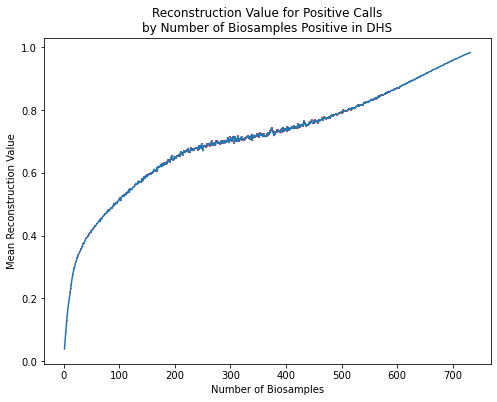

In [63]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

plt.errorbar(np.arange(1, 733), 
             num_bio_poscalls_recon_mean, 
             yerr=np.abs(num_bio_poscalls_recon_95ci - num_bio_poscalls_recon_mean),
             ecolor='r')

# plt.xlim([0, 5])

plt.xlabel('Number of Biosamples')
plt.ylabel('Mean Reconstruction Value')
plt.title('Reconstruction Value for Positive Calls\nby Number of Biosamples Positive in DHS')

In [56]:
np.argmax(np.bincount(pos_call_num_biosamples_arr[pos_call_recon_arr==0]))

18

Text(0.5, 1.0, 'Number of Biosamples for Positive Calls')

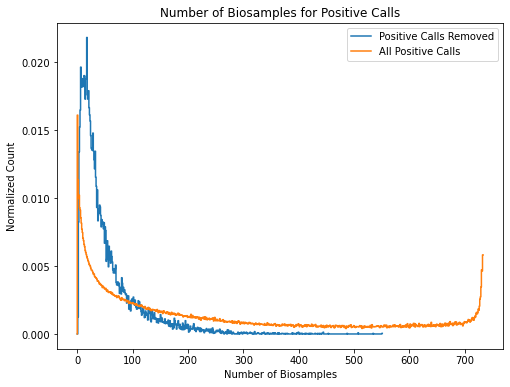

In [52]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

y = np.bincount(pos_call_num_biosamples_arr[pos_call_recon_arr==0]) / np.sum(np.bincount(pos_call_num_biosamples_arr[pos_call_recon_arr==0]))
x = np.arange(len(y))
plt.step(x, y)

y = np.bincount(pos_call_num_biosamples_arr) / np.sum(np.bincount(pos_call_num_biosamples_arr))
x = np.arange(len(y))
plt.step(x, y)

plt.legend(['Positive Calls Removed', 'All Positive Calls'])

plt.xlabel('Number of Biosamples')
plt.ylabel('Normalized Count')
plt.title('Number of Biosamples for Positive Calls')

In [41]:
num_bio_poscalls_percent_comp_agreement = []
for i in range(1, 733):
    #top comps of basis and mixture for each call for each num_biosample
    num_bio_specific_basis_top_comp = pos_call_basis_top_comp_arr[pos_call_num_biosamples_arr==i]
    num_bio_specific_mixture_top_comp = pos_call_mixture_top_comp_arr[pos_call_num_biosamples_arr==i]
    #find number of agreements in comps
    num_comp_agreements = len(np.arange(len(num_bio_specific_basis_top_comp))[num_bio_specific_basis_top_comp == 
                                                                              num_bio_specific_mixture_top_comp])
    #total number of calls
    num_calls = len(num_bio_specific_basis_top_comp)
    num_bio_poscalls_percent_comp_agreement.append(num_comp_agreements/num_calls)
num_bio_poscalls_percent_comp_agreement = np.array(num_bio_poscalls_percent_comp_agreement)

Text(0.5, 1.0, 'Percent NMF Component Agreement Between\nBiosample and DHS for Positive Calls')

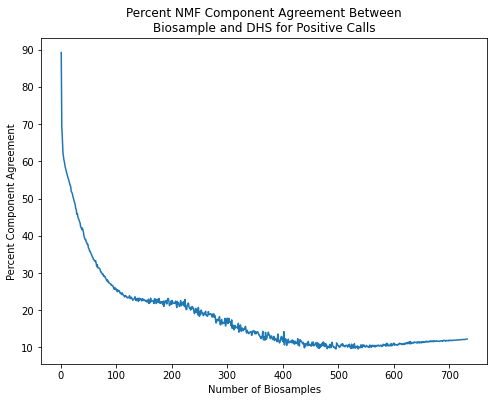

In [43]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

plt.plot(np.arange(1, 733), 
         num_bio_poscalls_percent_comp_agreement*100)

# plt.xlim([0, 30])

plt.xlabel('Number of Biosamples')
plt.ylabel('Percent Component Agreement')
plt.title('Percent NMF Component Agreement Between\nBiosample and DHS for Positive Calls')

In [178]:
np.where(num_biosamples_per_DHS_ori==732)[0][:10]

array([  842,  3716, 33279, 35207, 43955, 45539, 47154, 48260, 56030,
       56338])

In [64]:
dhs = 45539
describe(reconstruction[:, dhs][cycle0_dhs_arr[:, dhs]]), reconstruction[:, dhs][~cycle0_dhs_arr[:, dhs]]

(DescribeResult(nobs=732, minmax=(0.45921206, 1.2243947), mean=0.98344064, variance=0.01574649, skewness=-1.117543223482013, kurtosis=1.4382012873016539),
 array([0.64565617], dtype=float32))

**Biosample 44**

In [32]:
print(np.where(removed_biosample_inds==44)[0].shape)
print(np.where(added_biosample_inds==44)[0].shape)
print(np.where(flipped_biosample_inds==44)[0].shape)

(130,)
(1757,)
(1887,)


In [33]:
#for biosample 44, what are the removed DHS top comps
removed_44_top_comps = np.bincount(mixture_all_cycles_top_comp[0][removed_DHS_inds[np.where(removed_biosample_inds==44)[0]]])
removed_44_top_comps = np.append(removed_44_top_comps, 0)
print('counts', removed_44_top_comps)
removed_44_top_comp_enrichment = removed_44_top_comps/np.sum(removed_44_top_comps)/expected_comp_ratio
print('ooe', removed_44_top_comp_enrichment)

counts [ 1  0  0  0 39  0  1 20 10 34  0  3 13  3  6  0]
ooe [0.17523933 0.         0.         0.         3.84582501 0.
 0.10427196 1.1974562  2.32440625 5.90321218 0.         0.38216804
 2.48263283 0.97717626 0.88834777 0.        ]


Text(0.5, 1.0, 'Component Enrichment for Removed Calls\nfrom Biosample 44: hESCT0')

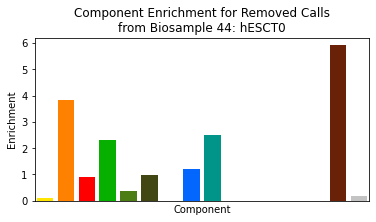

In [41]:
fig = comp_enrichment_wrapper(removed_44_top_comp_enrichment)
plt.title('Component Enrichment for Removed Calls\nfrom Biosample 44: hESCT0')

In [42]:
#for biosample 44, what are the added DHS top comps
added_44_top_comps = np.bincount(mixture_all_cycles_top_comp[0][added_DHS_inds[np.where(added_biosample_inds==44)[0]]])
added_44_top_comps = np.append(added_44_top_comps, [0, 0, 0])
print('counts', added_44_top_comps)
added_44_top_comp_enrichment = added_44_top_comps/np.sum(added_44_top_comps)/expected_comp_ratio
print('ooe', added_44_top_comp_enrichment)

counts [ 113   25 1163  345   40    2    0    0    0   55    2    6    6    0
    0    0]
ooe [1.46514838 0.90962864 3.79474374 1.74197447 0.29184785 0.02837641
 0.         0.         0.         0.70655139 0.04242725 0.05655304
 0.08477972 0.         0.         0.        ]


Text(0.5, 1.0, 'Component Enrichment for Added Calls\nto Biosample 44: hESCT0')

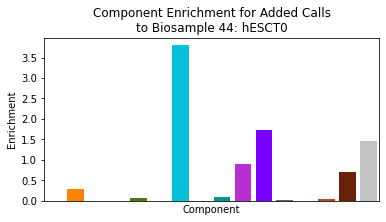

In [43]:
fig = comp_enrichment_wrapper(added_44_top_comp_enrichment)
plt.title('Component Enrichment for Added Calls\nto Biosample 44: hESCT0')

In [75]:
removed_44_max_signal = removed_max_signal_info_wrapper(44)
print('median', np.median(removed_44_max_signal))
print()
added_44_max_signal = added_max_signal_info_wrapper(44)
print('median', np.median(added_44_max_signal))

DescribeResult(nobs=130, minmax=(0.137048, 1.8813), mean=0.4469243846153846, variance=0.08370593257037806, skewness=2.004622462162727, kurtosis=4.943687122065402)
ModeResult(mode=array([0.199343]), count=array([5]))
median 0.35092650000000003

DescribeResult(nobs=1757, minmax=(0.0, 10.5029), mean=0.6951096654297096, variance=0.9754897228791908, skewness=4.113581869728873, kurtosis=22.022007459481916)
ModeResult(mode=array([0.303167]), count=array([22]))
median 0.39038


Text(0.5, 1.0, 'Greater Signal in Added Calls Compared to Removed Calls\nfor Biosample 44: hESCT0')

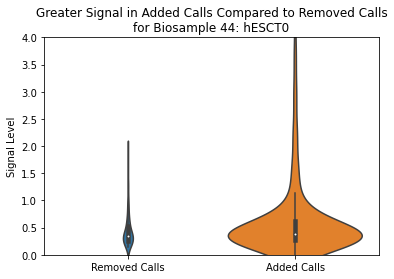

In [72]:
max_violin_y_44 = np.append(removed_44_max_signal, added_44_max_signal)
max_violin_x_44 = np.append(np.zeros(len(removed_44_max_signal)), np.ones(len(added_44_max_signal)))

fig = plt.figure()
fig.patch.set_facecolor('white')

sns.violinplot(x=max_violin_x_44, y=max_violin_y_44, scale='count', gridsize=1000, linewidth=1.5)
plt.ylim([0, 4])
# plt.yticks(np.arange(30)[::2])


plt.xticks([0, 1], ['Removed Calls', 'Added Calls'])
plt.ylabel('Signal Level')
plt.title('Greater Signal in Added Calls Compared to Removed Calls\nfor Biosample 44: hESCT0')

In [398]:
comp_specific_removed_44_mean_signal = removed_max_signal_info_wrapper_by_comp(44)
print(comp_specific_removed_44_mean_signal[official_order])
print()
comp_specific_added_44_mean_signal = added_max_signal_info_wrapper_by_comp(44)
print(comp_specific_added_44_mean_signal[official_order])

[0.199343   0.54883213 0.470671   0.3783365  0.30039867 0.506663
        nan 0.3833199  0.44500754        nan        nan        nan
        nan        nan 0.40723618 0.170272  ]

[       nan 0.60706158        nan        nan 0.7676085         nan
 0.66120902        nan 0.89358167 1.29356994 0.54299285 0.14535435
        nan 0.226337   0.52516293 1.49356517]


In [81]:
comps_for_heatmap[basis_all_cycles_top_comp[0, [44, 715, 102]]]

array(['Primitive / embryonic', 'Primitive / embryonic', 'Stromal B'],
      dtype='<U23')

**Biosample 715**

In [49]:
print(np.where(removed_biosample_inds==715)[0].shape)
print(np.where(added_biosample_inds==715)[0].shape)
print(np.where(flipped_biosample_inds==715)[0].shape)

(610,)
(479,)
(1089,)


In [50]:
#for biosample 715, what are the removed DHS top comps
removed_715_top_comps = np.bincount(mixture_all_cycles_top_comp[0][removed_DHS_inds[np.where(removed_biosample_inds==715)[0]]])
print('counts', removed_715_top_comps)
removed_715_top_comp_enrichment = removed_715_top_comps/np.sum(removed_715_top_comps)/expected_comp_ratio
print('ooe', removed_715_top_comp_enrichment)

counts [  4  38   0  76 158  71  10  58  18  61  12   0  36  15  35  18]
ooe [0.14938434 3.98244368 0.         1.10529501 3.32043908 2.90153431
 0.22221894 0.74006719 0.89165748 2.25711054 0.73322633 0.
 1.46516036 1.0412534  1.10436676 0.56231628]


Text(0.5, 1.0, 'Component Enrichment for Removed Calls\nfrom Biosample 715: DE')

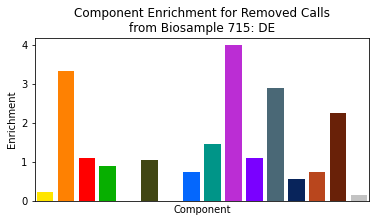

In [51]:
fig = comp_enrichment_wrapper(removed_715_top_comp_enrichment)
plt.title('Component Enrichment for Removed Calls\nfrom Biosample 715: DE')

In [52]:
#for biosample 715, what are the added DHS top comps
added_715_top_comps = np.bincount(mixture_all_cycles_top_comp[0][added_DHS_inds[np.where(added_biosample_inds==715)[0]]])
added_715_top_comps = np.append(added_715_top_comps, [0, 0, 0, 0])
print('counts', added_715_top_comps)
added_715_top_comp_enrichment = added_715_top_comps/np.sum(added_715_top_comps)/expected_comp_ratio
print('ooe', added_715_top_comp_enrichment)

counts [ 13  12 341  93   5   0   0   0   0  11   0   4   0   0   0   0]
ooe [0.61827654 1.6015541  4.08125156 1.72243122 0.13381437 0.
 0.         0.         0.         0.51833436 0.         0.13829323
 0.         0.         0.         0.        ]


Text(0.5, 1.0, 'Component Enrichment for Added Calls\nto Biosample 715: DE')

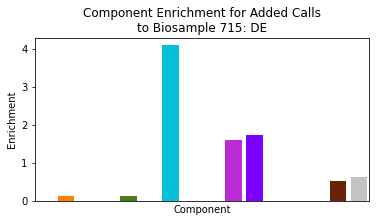

In [53]:
fig = comp_enrichment_wrapper(added_715_top_comp_enrichment)
plt.title('Component Enrichment for Added Calls\nto Biosample 715: DE')

In [76]:
removed_715_max_signal = removed_max_signal_info_wrapper(715)
print('median', np.median(removed_715_max_signal))
print()
added_715_max_signal = added_max_signal_info_wrapper(715)
print('median', np.median(added_715_max_signal))

DescribeResult(nobs=610, minmax=(0.024044, 2.76068), mean=0.16003739196721314, variance=0.031229419390845857, skewness=8.090200001683634, kurtosis=97.27398161385727)
ModeResult(mode=array([0.0633886]), count=array([13]))
median 0.12022

DescribeResult(nobs=479, minmax=(0.0, 10.8657), mean=0.66578330480167, variance=0.816314642161447, skewness=5.712667246694357, kurtosis=48.573595265050784)
ModeResult(mode=array([0.25574]), count=array([6]))
median 0.338801


Text(0.5, 1.0, 'Greater Signal in Added Calls Compared to Removed Calls\nfor Biosample 715: DE')

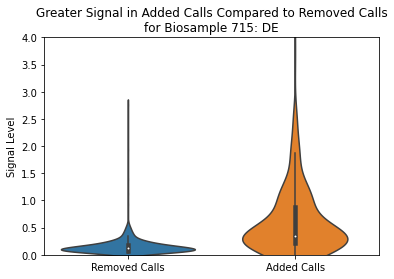

In [57]:
max_violin_y_715 = np.append(removed_715_max_signal, added_715_max_signal)
max_violin_x_715 = np.append(np.zeros(len(removed_715_max_signal)), np.ones(len(added_715_max_signal)))

fig = plt.figure()
fig.patch.set_facecolor('white')

sns.violinplot(x=max_violin_x_715, y=max_violin_y_715, scale='count', gridsize=1000, linewidth=1.5)
plt.ylim([0, 4])
# plt.yticks(np.arange(30)[::2])


plt.xticks([0, 1], ['Removed Calls', 'Added Calls'])
plt.ylabel('Signal Level')
plt.title('Greater Signal in Added Calls Compared to Removed Calls\nfor Biosample 715: DE')

In [397]:
comp_specific_removed_715_mean_signal = removed_max_signal_info_wrapper_by_comp(715)
print(comp_specific_removed_715_mean_signal[official_order])
print()
comp_specific_added_715_mean_signal = added_max_signal_info_wrapper_by_comp(715)
print(comp_specific_added_715_mean_signal[official_order])

[0.13399038 0.18828435 0.11859601 0.15749999        nan 0.12211403
        nan 0.16103414 0.16168959 0.08938824 0.11927063 0.13816806
 0.13187737 0.13479188 0.17938005 1.3377175 ]

[       nan 0.34973           nan        nan 0.6715905         nan
 0.62364279        nan        nan 0.94481708 0.58690271        nan
        nan        nan 0.758874   2.11889446]


**Biosample 102 (NHLF)**

In [63]:
print(np.where(removed_biosample_inds==102)[0].shape)
print(np.where(added_biosample_inds==102)[0].shape)
print(np.where(flipped_biosample_inds==102)[0].shape)

(5,)
(953,)
(958,)


In [64]:
#for biosample 102, what are the removed DHS top comps
removed_102_top_comps = np.bincount(mixture_all_cycles_top_comp[0][removed_DHS_inds[np.where(removed_biosample_inds==102)[0]]])
print('counts', removed_102_top_comps)
removed_102_top_comps = np.append(removed_102_top_comps, [0])
removed_102_top_comp_enrichment = removed_102_top_comps/np.sum(removed_102_top_comps)/expected_comp_ratio
print('ooe', removed_102_top_comp_enrichment)

counts [0 0 2 0 1 0 0 0 0 0 0 0 0 0 2]
ooe [0.         0.         2.2931607  0.         2.56388334 0.
 0.         0.         0.         0.         0.         0.
 0.         0.         7.69901402 0.        ]


Text(0.5, 1.0, 'Component Enrichment for Removed Calls\nfrom Biosample 102: NHLF')

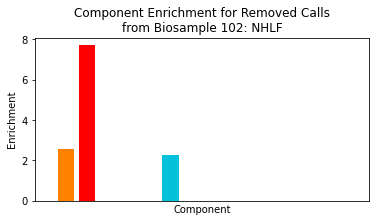

In [65]:
fig = comp_enrichment_wrapper(removed_102_top_comp_enrichment)
plt.title('Component Enrichment for Removed Calls\nfrom Biosample 102: NHLF')

In [66]:
np.sum(added_102_top_comps)+np.sum(removed_102_top_comps)

958

In [67]:
#for biosample 102, what are the added DHS top comps
added_102_top_comps = np.bincount(mixture_all_cycles_top_comp[0][added_DHS_inds[np.where(added_biosample_inds==102)[0]]])
added_102_top_comps = np.append(added_102_top_comps, [0, 0, 0])
print('counts', added_102_top_comps)
added_102_top_comp_enrichment = added_102_top_comps/np.sum(added_102_top_comps)/expected_comp_ratio
print('ooe', added_102_top_comp_enrichment)

counts [104  13 240 565  10  14   0   0   0   4   1   0   2   0   0   0]
ooe [2.48608153 0.87205993 1.4437528  5.2595671  0.13451644 0.36621348
 0.         0.         0.         0.09473706 0.03911053 0.
 0.05210142 0.         0.         0.        ]


Text(0.5, 1.0, 'Component Enrichment for Added Calls\nto Biosample 102: NHLF')

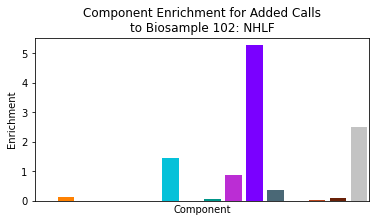

In [68]:
fig = comp_enrichment_wrapper(added_102_top_comp_enrichment)
plt.title('Component Enrichment for Added Calls\nto Biosample 102: NHLF')

In [78]:
removed_102_max_signal = removed_max_signal_info_wrapper(102)
print('median', np.median(removed_102_max_signal))
print()
added_102_max_signal = added_max_signal_info_wrapper(102)
print('median', np.median(added_102_max_signal))

DescribeResult(nobs=5, minmax=(0.131527, 0.245748), mean=0.181369, variance=0.002327742976499999, skewness=0.3906195461442845, kurtosis=-1.4937395691439104)
ModeResult(mode=array([0.131527]), count=array([1]))
median 0.159217

DescribeResult(nobs=953, minmax=(0.0242287, 10.1657), mean=0.36188658090241344, variance=0.4920533140771757, skewness=7.741583136890265, kurtosis=75.99079139886982)
ModeResult(mode=array([0.145372]), count=array([19]))
median 0.214597


Text(0.5, 1.0, 'Greater Signal in Added Calls Compared to Removed Calls\nfor Biosample 102: NHLF')

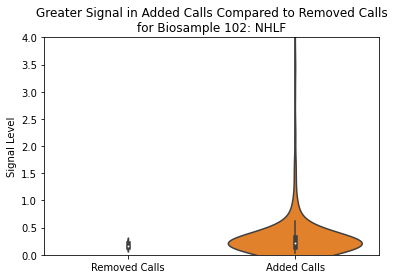

In [71]:
max_violin_y_102 = np.append(removed_102_max_signal, added_102_max_signal)
max_violin_x_102 = np.append(np.zeros(len(removed_102_max_signal)), np.ones(len(added_102_max_signal)))

fig = plt.figure()
fig.patch.set_facecolor('white')

sns.violinplot(x=max_violin_x_102, y=max_violin_y_102, scale='count', gridsize=1000, linewidth=1.5)
plt.ylim([0, 4])
# plt.yticks(np.arange(30)[::2])


plt.xticks([0, 1], ['Removed Calls', 'Added Calls'])
plt.ylabel('Signal Level')
plt.title('Greater Signal in Added Calls Compared to Removed Calls\nfor Biosample 102: NHLF')

In [70]:
comp_specific_removed_102_mean_signal = removed_max_signal_info_wrapper_by_comp(102)
print(comp_specific_removed_102_mean_signal[official_order])
print()
comp_specific_added_102_mean_signal = added_max_signal_info_wrapper_by_comp(102)
print(comp_specific_added_102_mean_signal[official_order])

[      nan 0.218058  0.145372        nan       nan       nan 0.1990215
       nan       nan       nan       nan       nan       nan       nan
       nan       nan]

[       nan 0.4939189         nan        nan        nan        nan
 0.28229289        nan 0.5970625  3.01234644 0.27983353 1.30711281
        nan 0.128066   0.7536857  0.50274489]


**Basis and Mixture Analysis**

In [29]:
np.round((basis_all_cycles[0, [411, 486, 531, 719, 728], :]- basis_all_cycles[1, [411, 486, 531, 719, 728], :])*10, 3)

array([[ 0.044,  0.   ,  0.   ,  0.   ,  0.   ,  0.   ,  0.   ,  0.   ,
         0.   , -0.192,  0.   ,  0.   ,  0.   ,  0.   ,  0.   ,  0.   ],
       [ 0.037,  0.   ,  0.   ,  0.   ,  0.   ,  0.   ,  0.   ,  0.   ,
         0.   , -0.186,  0.   ,  0.   ,  0.   ,  0.   ,  0.   ,  0.   ],
       [ 0.018,  0.   ,  0.   ,  0.   ,  0.   ,  0.   ,  0.   ,  0.   ,
         0.   , -0.182,  0.   ,  0.   ,  0.   ,  0.   ,  0.   ,  0.   ],
       [-0.035,  0.   , -0.027,  0.   ,  0.   ,  0.   ,  0.01 ,  0.   ,
         0.   ,  0.025,  0.   ,  0.042,  0.   ,  0.   ,  0.   ,  0.   ],
       [ 0.021,  0.   , -0.05 ,  0.   ,  0.025,  0.   , -0.007, -0.008,
        -0.079,  0.107, -0.02 ,  0.006, -0.018,  0.   ,  0.   ,  0.   ]],
      dtype=float32)

In [30]:
basis_all_cycles[0, [411], :]

array([[1.6800407, 0.       , 0.       , 0.       , 0.       , 0.       ,
        0.       , 0.       , 0.       , 1.6576077, 0.       , 0.       ,
        0.       , 0.       , 0.       , 0.       ]], dtype=float32)

In [31]:
basis_all_cycles[1, [411], :]

array([[1.6756366, 0.       , 0.       , 0.       , 0.       , 0.       ,
        0.       , 0.       , 0.       , 1.6767769, 0.       , 0.       ,
        0.       , 0.       , 0.       , 0.       ]], dtype=float32)

In [32]:
describe(np.sum(np.abs(basis_all_cycles[0]-basis_all_cycles[1]), axis=1))

DescribeResult(nobs=733, minmax=(0.0008324459, 0.31179187), mean=0.023573212, variance=0.00086250267, skewness=4.4308720288725745, kurtosis=29.147644493323014)

In [33]:
np.sum(np.abs(basis_all_cycles[0]-basis_all_cycles[1]), axis=1)[[411, 486, 531, 719, 728]]

array([0.02357328, 0.02225065, 0.01992869, 0.01391493, 0.03410542],
      dtype=float32)

In [ ]:
# 411
# 486
# 531
# 719
# 728


In [34]:
np.argsort(-np.bincount(np.append(removed_biosample_inds, added_biosample_inds))).shape

(733,)

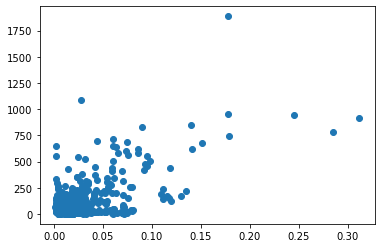

In [37]:

fig = plt.figure()
fig.patch.set_facecolor('white')

plt.scatter(np.sum(np.abs(basis_all_cycles[0]-basis_all_cycles[1]), axis=1), 
           np.bincount(np.append(removed_biosample_inds, added_biosample_inds)))

**Signal Average**

In [406]:
removed_max_signal = DHS_max_signal_array[removed_biosample_inds, removed_DHS_inds]
added_max_signal = DHS_max_signal_array[added_biosample_inds, added_DHS_inds]
print(describe(added_max_signal))
print('median =', np.median(added_max_signal))
print()
print(describe(removed_max_signal))
print('median =', np.median(removed_max_signal))

DescribeResult(nobs=46842, minmax=(0.0, 53.5695), mean=1.0898717149763033, variance=3.7363922623445203, skewness=5.844128618222362, kurtosis=62.89684395339228)
median = 0.389075

DescribeResult(nobs=22450, minmax=(0.024044, 104.351), mean=0.8249058282405345, variance=1.7535909715199902, skewness=37.67913839384593, kurtosis=2416.8957162695165)
median = 0.6153
